# Kunci Lab 0: Mulai dari Nol

Jawaban latihan Lab 0.



## Persiapan: alamat data



**Alur sesi:** kita membaca tabel dan menjalankan model pertama. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah arti satu baris data, sumbu grafik, dan hasil prediksi.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## Latihan 1 dan 2: baca data dan hitung rata-rata



<!-- kamus_variabel:uts_4.csv -->

### Kenali data: Angka harapan hidup

**Data:** `data/uts_4.csv`. **Satu baris:** satu negara pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Angka_Harapan_Hidup` | Rata-rata lama hidup yang diharapkan menurut indikator pada contoh. | Tahun | Y: target |
| `X1_Pengeluaran_Kesehatan` | Pengeluaran kesehatan per penduduk (per kapita). | Uang per kapita; mata uang/periode tidak dirinci | X: penjelas |
| `X2_Tingkat_Imunisasi` | Persentase anak yang memperoleh imunisasi. | Persen; jenis imunisasi tidak dirinci | X: penjelas |
| `X3_Konsumsi_Kalori` | Rata-rata konsumsi energi makanan per hari. | Kalori harian; rincian satuan energi mengikuti sumber | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [3]:
harapan_hidup = pd.read_csv(URL_DATA + "uts_4.csv")
print("Jumlah observasi:", len(harapan_hidup))
harapan_hidup.head()


Jumlah observasi: 50


,Y_Angka_Harapan_Hidup,X1_Pengeluaran_Kesehatan,X2_Tingkat_Imunisasi,X3_Konsumsi_Kalori
0,75.5,1550,92,2850
1,72.1,850,85,2600
2,81.2,4500,98,3300
3,82.5,5500,99,3450
4,68.5,350,75,2300


In [4]:
print(
    "Rata-rata harapan hidup :", round(harapan_hidup["Y_Angka_Harapan_Hidup"].mean(), 2)
)
print(
    "Rata-rata imunisasi     :", round(harapan_hidup["X2_Tingkat_Imunisasi"].mean(), 2)
)


Rata-rata harapan hidup : 76.95
Rata-rata imunisasi     : 91.86


## Latihan 3: regresi sederhana



In [5]:
sampel_model = harapan_hidup[
    ["Y_Angka_Harapan_Hidup", "X1_Pengeluaran_Kesehatan"]
].dropna()
X_model = sampel_model[["X1_Pengeluaran_Kesehatan"]]
y_model = sampel_model["Y_Angka_Harapan_Hidup"]

model = LinearRegression()
model.fit(X_model, y_model)

koefisien_model = pd.Series(model.coef_, index=X_model.columns)
koefisien_model.loc["Intercept"] = model.intercept_


### Lihat hasil model: Harapan hidup (tahun)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

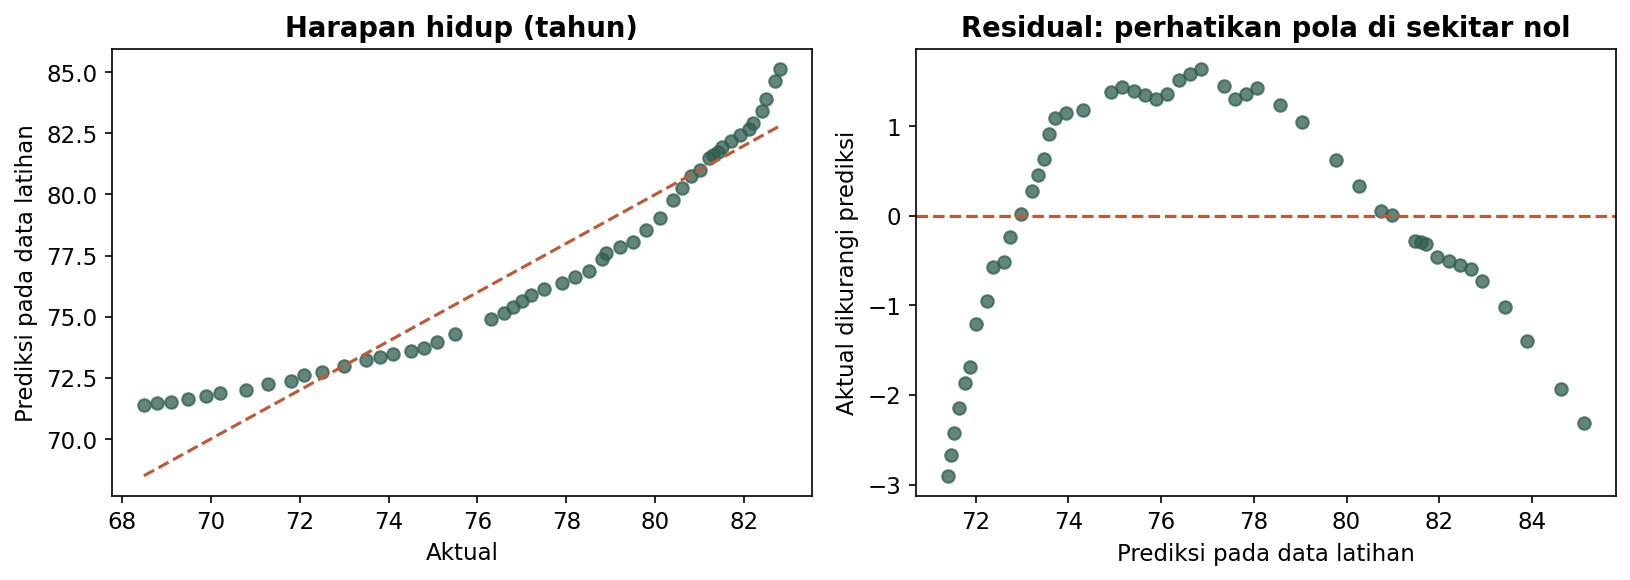

In [6]:
prediksi_visual = model.predict(X_model)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model.min(), y_model.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Harapan hidup (tahun)")
axes[1].scatter(prediksi_visual, y_model - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya. Lengkungan residual mengingatkan bahwa contoh regresi awal ini belum menyelesaikan seluruh persoalan spesifikasi; pertanyaan tentang bentuk model dilanjutkan pada Sesi 2.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [7]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model = sm.OLS(
    y_model,
    sm.add_constant(X_model, has_constant="add").rename(columns={"const": "Intercept"}),
).fit()
print(koefisien_model.round(5))
print(uji_model.pvalues.round(4))


X1_Pengeluaran_Kesehatan     0.00243
Intercept                   70.55237
dtype: float64
Intercept                   0.0
X1_Pengeluaran_Kesehatan    0.0
dtype: float64


Kesimpulan: koefisien pengeluaran kesehatan 0,00243 dengan p-value
0,0000, jadi signifikan. Setiap tambahan satu unit pengeluaran kesehatan
diiringi kenaikan harapan hidup 0,00243 tahun. R kuadrat model ini
sekitar 0,91.
